In [14]:
from pathlib import Path
from collections import Counter, defaultdict
import random
from PIL import Image
import matplotlib.pyplot as plt

REAL_ROOT = Path("/home/student/cow_frontal_face_dataset/INDIVIDUAL SUBJECTS Data")
assert REAL_ROOT.exists(), "Inner dataset folder not found"

print("Real dataset root:", REAL_ROOT)


Real dataset root: /home/student/cow_frontal_face_dataset/INDIVIDUAL SUBJECTS Data


In [15]:
identity_dirs = sorted([p for p in REAL_ROOT.iterdir() if p.is_dir()])

print("Number of identities (cows):", len(identity_dirs))
print("\nSample identity names:")
for d in identity_dirs[:10]:
    print(" ", d.name)


Number of identities (cows): 459

Sample identity names:
  cattle-001
  cattle-002
  cattle-003
  cattle-004
  cattle-005
  cattle-006
  cattle-007
  cattle-008
  cattle-009
  cattle-010


In [16]:
IMAGE_EXTS = {".jpg", ".jpeg", ".png"}

images_per_id = {}

for d in identity_dirs:
    images_per_id[d.name] = sum(
        1 for f in d.iterdir()
        if f.suffix.lower() in IMAGE_EXTS
    )

images_per_id


{'cattle-001': 9,
 'cattle-002': 5,
 'cattle-003': 3,
 'cattle-004': 5,
 'cattle-005': 3,
 'cattle-006': 4,
 'cattle-007': 3,
 'cattle-008': 3,
 'cattle-009': 6,
 'cattle-010': 7,
 'cattle-011': 3,
 'cattle-012': 3,
 'cattle-013': 8,
 'cattle-014': 1,
 'cattle-015': 3,
 'cattle-016': 4,
 'cattle-017': 3,
 'cattle-018': 6,
 'cattle-019': 4,
 'cattle-020': 4,
 'cattle-021': 2,
 'cattle-022': 7,
 'cattle-023': 8,
 'cattle-024': 5,
 'cattle-025': 2,
 'cattle-026': 5,
 'cattle-027': 1,
 'cattle-028': 4,
 'cattle-029': 7,
 'cattle-030': 2,
 'cattle-031': 8,
 'cattle-032': 6,
 'cattle-033': 13,
 'cattle-034': 11,
 'cattle-035': 4,
 'cattle-036': 1,
 'cattle-037': 3,
 'cattle-038': 2,
 'cattle-039': 1,
 'cattle-040': 1,
 'cattle-041': 4,
 'cattle-042': 3,
 'cattle-043': 4,
 'cattle-044': 6,
 'cattle-045': 1,
 'cattle-046': 3,
 'cattle-047': 4,
 'cattle-048': 6,
 'cattle-049': 10,
 'cattle-050': 2,
 'cattle-051': 5,
 'cattle-052': 9,
 'cattle-053': 5,
 'cattle-054': 3,
 'cattle-055': 3,
 'cattl

In [17]:
counts = list(images_per_id.values())

print("Total identities:", len(counts))
print("Total images:", sum(counts))
print("Min images per identity:", min(counts))
print("Max images per identity:", max(counts))
print("Average images per identity:", sum(counts) / len(counts))


Total identities: 459
Total images: 2847
Min images per identity: 1
Max images per identity: 38
Average images per identity: 6.2026143790849675


In [18]:
sorted(images_per_id.items(), key=lambda x: x[1])[:10]


[('cattle-014', 1),
 ('cattle-027', 1),
 ('cattle-036', 1),
 ('cattle-039', 1),
 ('cattle-040', 1),
 ('cattle-045', 1),
 ('cattle-057', 1),
 ('cattle-062', 1),
 ('cattle-064', 1),
 ('cattle-065', 1)]

In [19]:
sorted(images_per_id.items(), key=lambda x: x[1], reverse=True)[:10]


[('cattle-325', 38),
 ('cattle-181', 27),
 ('cattle-149', 24),
 ('cattle-158', 24),
 ('cattle-141', 21),
 ('cattle-251', 19),
 ('cattle-143', 18),
 ('cattle-174', 18),
 ('cattle-394', 18),
 ('cattle-241', 17)]

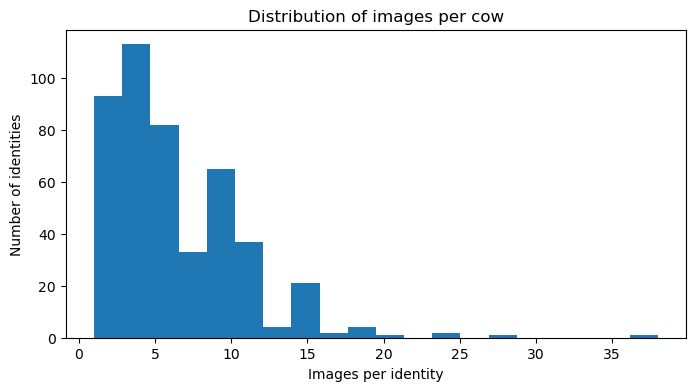

In [20]:
plt.figure(figsize=(8, 4))
plt.hist(counts, bins=20)
plt.xlabel("Images per identity")
plt.ylabel("Number of identities")
plt.title("Distribution of images per cow")
plt.show()


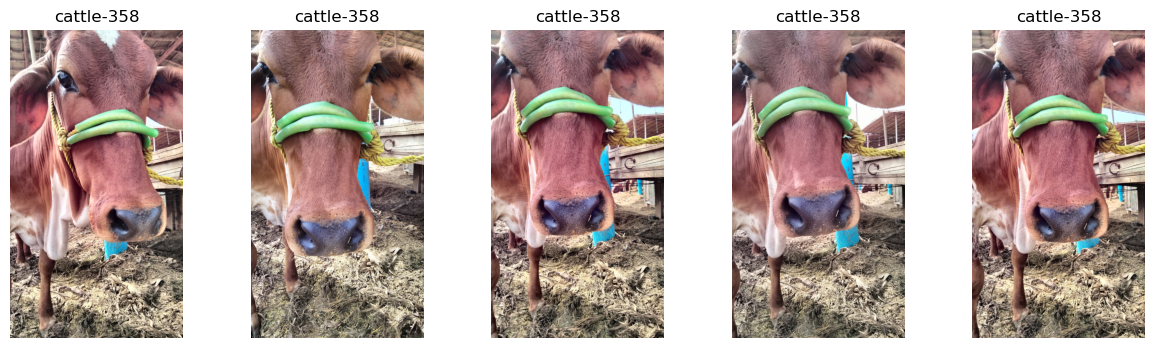

In [21]:
cow = random.choice(identity_dirs)
imgs = list(cow.iterdir())

sample_imgs = random.sample(imgs, min(5, len(imgs)))

plt.figure(figsize=(15, 4))
for i, img_path in enumerate(sample_imgs):
    img = Image.open(img_path)
    plt.subplot(1, len(sample_imgs), i + 1)
    plt.imshow(img)
    plt.axis("off")
    plt.title(cow.name)

plt.show()


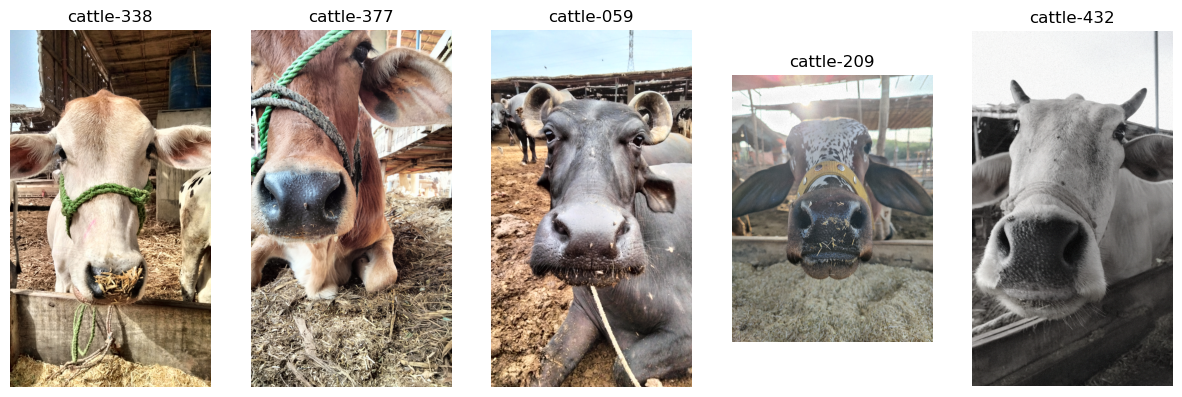

In [22]:
sample_cows = random.sample(identity_dirs, 5)

plt.figure(figsize=(15, 6))
for i, cow in enumerate(sample_cows):
    img_path = random.choice(list(cow.iterdir()))
    img = Image.open(img_path)

    plt.subplot(1, 5, i + 1)
    plt.imshow(img)
    plt.axis("off")
    plt.title(cow.name)

plt.show()


In [23]:
resolution_counter = Counter()

for cow in identity_dirs:
    for img_path in cow.iterdir():
        if img_path.suffix.lower() in IMAGE_EXTS:
            with Image.open(img_path) as img:
                resolution_counter[img.size] += 1

resolution_counter.most_common(10)


[((2336, 4160), 1332),
 ((3648, 5472), 777),
 ((2608, 4624), 411),
 ((3008, 4000), 315),
 ((4624, 2608), 10),
 ((3468, 4624), 1),
 ((3120, 4160), 1)]

In [24]:
resolution_per_id = defaultdict(set)

for cow in identity_dirs:
    for img_path in cow.iterdir():
        if img_path.suffix.lower() in IMAGE_EXTS:
            with Image.open(img_path) as img:
                resolution_per_id[cow.name].add(img.size)

# How many cows have multiple resolutions?
multi_res = {k: v for k, v in resolution_per_id.items() if len(v) > 1}

len(multi_res), list(multi_res.items())[:3]


(7,
 [('cattle-253', {(2336, 4160), (2608, 4624)}),
  ('cattle-254', {(2336, 4160), (2608, 4624)}),
  ('cattle-273', {(2608, 4624), (4624, 2608)})])

In [25]:
bad = []

for cow in identity_dirs:
    for img_path in cow.iterdir():
        try:
            Image.open(img_path).verify()
        except:
            bad.append(img_path)

print("Corrupt images:", len(bad))
bad[:5]


Corrupt images: 2


[PosixPath('/home/student/cow_frontal_face_dataset/INDIVIDUAL SUBJECTS Data/cattle-001/.ipynb_checkpoints'),
 PosixPath('/home/student/cow_frontal_face_dataset/INDIVIDUAL SUBJECTS Data/cattle-033/.ipynb_checkpoints')]